# Proyecto final - Curso Aprendizaje Automático - EVIA II

## **Título**: Predicción de emisiones de CO y NOx desde chimeneas industriales usando modelos de regresión de ML

El problema específico que aborda este trabajo se centra en la predicción de las concentraciones de monóxido de carbono (CO) y óxidos de nitrógeno (NOx) que emiten las turbinas de gas

**Dataset:**
- Gas Turbine CO and NOx Emission Data Set [Dataset]. (2019). UCI Machine Learning Repository. https://doi.org/10.24432/C5WC95.


**Información básica de las variables:**

|Variable|Abreviatura|Unidades|Mín|Máx|Media
|-|-|-|-|-|-
|Temperatura ambiental|[AT]|(◦C)|–6.23|37.10|17.71
|Presión ambiental|[AP]|(mbar)|985.85|1036.56|1013.07
|Humedad ambiental|[AH]|(%)|24.08|100.20|77.87
|Diferencia de presión del filtro de aire|[AFDP]|(mbar)|2.09|7.61|3.93
|Presión de salida de la turbina de gas|[GTEP]|(mbar)|17.70|40.72|25.56
|Temperatura a la entrada de la turbina|[TIT]|(◦C)|1000.85|1100.89|1081.43
|Temperatura a la salida de la turbina|[TAT]|(◦C)|511.04|550.61|546.16
|Presión de descarga del compresor|[CDP]|(mbar)|9.85|15.16|12.06
|Rendimiento energético de la turbina|[TEY]|(MWH)|100.02|179.50|133.51
|Concentración de monóxido de carbono|[CO]|(mg/m3)|0.00|44.10|2.37

In [31]:
!pip install ucimlrepo

### Importar el dataset

In [32]:
# Se importa el repositorio con la librería ucimlrepo

from ucimlrepo import fetch_ucirepo

# Adquirir el dataset
gas_turbine_co_and_nox_emission_data_set = fetch_ucirepo(id=551)

# data (como un pandas dataframes)
# X son las características
# Y es la varible objetivo
X = gas_turbine_co_and_nox_emission_data_set.data.features.drop(['CO', 'NOX'], axis=1)
y = gas_turbine_co_and_nox_emission_data_set.data.features[['CO']]

# metadata
print(gas_turbine_co_and_nox_emission_data_set.metadata)

# información de variables
print(X.describe())
print(y.describe())


{'uci_id': 551, 'name': 'Gas Turbine CO and NOx Emission Data Set', 'repository_url': 'https://archive.ics.uci.edu/dataset/551/gas+turbine+co+and+nox+emission+data+set', 'data_url': 'https://archive.ics.uci.edu/static/public/551/data.csv', 'abstract': 'The dataset contains 36733 instances of 11 sensor measures aggregated over one hour, from a gas turbine located in Turkey for the purpose of studying flue gas emissions, namely CO and NOx.', 'area': 'Computer Science', 'tasks': ['Regression', 'Clustering'], 'characteristics': ['Multivariate'], 'num_instances': 36733, 'num_features': 12, 'feature_types': ['Real'], 'demographics': [], 'target_col': None, 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2019, 'last_updated': 'Fri Mar 29 2024', 'dataset_doi': '10.24432/C5WC95', 'creators': [], 'intro_paper': None, 'additional_info': {'summary': "The dataset contains 36733 instances of 11 sensor measures aggregated over one hour (by mea

Se observan 36733 registros. Las variables son numéricas y no hay registros nulos.

### Estandarizar las variables

Para propósitos de esta solución se hará una estandarización de los datos, considerando la escala de los valores de las diferentes variables. Esto entre otras cosas, para evitar que las variables con valores más altos tengan un peso mayor en el modelo.

In [33]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, SGDRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd

# Estandarizar las características (X)
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X.drop(['year'],axis=1))
X_scaled_df = pd.DataFrame(X_scaled, columns=X.drop(['year'],axis=1).columns)

# Estandarizar la variable objetivo (y)
scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y)
y_scaled_df = pd.DataFrame(y_scaled, columns=y.columns)

df_scaled = pd.concat([X[['year']], X_scaled_df, y_scaled_df], axis=1)
df_scaled.describe()

,year,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO
count,36733.000000,3.673300e+04,3.673300e+04,3.673300e+04,3.673300e+04,3.673300e+04,3.673300e+04,3.673300e+04,3.673300e+04,3.673300e+04,3.673300e+04
mean,2012.985735,-1.176081e-16,-1.233647e-14,-5.570912e-16,-1.015144e-15,5.292366e-16,9.609823e-15,-8.300659e-15,9.888369e-16,-4.704326e-16,-7.427883e-17
std,1.418965,1.000014e+00,1.000014e+00,1.000014e+00,1.000014e+00,1.000014e+00,1.000014e+00,1.000014e+00,1.000014e+00,1.000014e+00,1.000014e+00
min,2011.000000,-3.215577e+00,-4.211524e+00,-3.719067e+00,-2.375059e+00,-1.874640e+00,-4.597825e+00,-5.132585e+00,-2.144032e+00,-2.028623e+00,-1.048368e+00
25%,2012.000000,-7.964882e-01,-6.606830e-01,-6.693112e-01,-7.363991e-01,-5.802810e-01,-5.490425e-01,-2.102398e-01,-5.798539e-01,-5.745191e-01,-5.259643e-01
50%,2013.000000,1.185304e-02,-7.274427e-02,1.799983e-01,1.574091e-02,-1.095835e-01,2.550115e-01,5.438962e-01,1.431620e-02,-8.773591e-02,-2.912386e-01
75%,2014.000000,7.992472e-01,6.080269e-01,7.958550e-01,5.832377e-01,8.334799e-01,8.879903e-01,5.672802e-01,6.769952e-01,7.296924e-01,2.079127e-01
max,2015.000000,2.603647e+00,3.640553e+00,1.544343e+00,4.761549e+00,3.611191e+00,1.110388e+00,6.505859e-01,2.944830e+00,2.845821e+00,1.844329e+01


### Preparación de los conjuntos de entrenamiento, validacion y prueba

Para mantener la continuidad con trabajos anteriores, se separan los datos de los años 2011 y 2012 para prueba, el año 2013 par validación y los años 2014 y 2015 para pruebas.

In [34]:
# Separar la data por años
train_data = df_scaled[(df_scaled['year'] >= 2014) & (df_scaled['year'] <= 2015)]
val_data = df_scaled[df_scaled['year'] == 2013]
test_data = df_scaled[(df_scaled['year'] >= 2011) & (df_scaled['year'] <= 2012)]

# Definir características (X) y variable objetivo (y) para cada set
X_train = train_data.drop(['year', 'CO'], axis=1)
y_train = train_data['CO']

X_val = val_data.drop(['year', 'CO'], axis=1)
y_val = val_data['CO']

X_test = test_data.drop(['year', 'CO'], axis=1)
y_test = test_data['CO']

print("Training set shape (X, y):", X_train.shape, y_train.shape)
print("Validation set shape (X, y):", X_val.shape, y_val.shape)
print("Test set shape (X, y):", X_test.shape, y_test.shape)

Training set shape (X, y): (14542, 9) (14542,)
Validation set shape (X, y): (7152, 9) (7152,)
Test set shape (X, y): (15039, 9) (15039,)


In [35]:
y_test.describe()

,CO
count,15039.000000
mean,-0.176771
std,0.982129
min,-1.048368
25%,-0.669312
50%,-0.434125
75%,-0.093726
max,18.443286


### Entrenamiento de los modelos

Se entrenarán modelos de Regresión linear, Ridge, Lasso y Descenso del Gradiente Estocástico (SGD)

In [36]:
# Initializar el modelo de regresión lineal
lr = LinearRegression()

# Entrenar el modelo
lr.fit(X_train, y_train)

# Realizar predicciones con el modelo sobre el set de validación
y_val_pred_lr = lr.predict(X_val)

# Evaluar el modelo sobre el set de validación
mse_val_lr = mean_squared_error(y_val, y_val_pred_lr)
r2_val_lr = r2_score(y_val, y_val_pred_lr)

print("Evaluación del modelo de Regresión lineal sobre el set de validación:")
print(f"Mean Squared Error (MSE): {mse_val_lr:.4f}")
print(f"R-squared (R2): {r2_val_lr:.4f}")

print("-" * 30)

# Inicializar el modelo de regresión Ridge
ridge = Ridge()

# Definir los hiperparámetros del modelo Ridge para el Grid Search
param_grid_ridge = {'alpha': [0.001, 0.01, 0.1, 1, 10, 100]}

# Initializar GridSearchCV para Ridge
grid_search_ridge = GridSearchCV(ridge, param_grid_ridge, cv=5, scoring='neg_mean_squared_error')

# Entrenar el modelo Ridge
grid_search_ridge.fit(X_train, y_train)

# Obtener el mejor modelo Ridge
best_ridge_model = grid_search_ridge.best_estimator_

# Realizar predicciones con el modelo sobre el set de validación
y_val_pred_ridge = best_ridge_model.predict(X_val)

# Evaluar el modelo sobre el set de validación
mse_val_ridge = mean_squared_error(y_val, y_val_pred_ridge)
r2_val_ridge = r2_score(y_val, y_val_pred_ridge)

print("Evaluación del modelo de Regresión Rigde sobre el set de validación:")
print(f"Mejores Hiperparametros: {grid_search_ridge.best_params_}")
print(f"Mean Squared Error (MSE): {mse_val_ridge:.4f}")
print(f"R-squared (R2): {r2_val_ridge:.4f}")

print("-" * 30)

# Inicializar el modelo de regresión Lasso
lasso = Lasso()

# Definir los hiperparámetros del modelo Lasso para el Grid Search
param_grid_lasso = {'alpha': [0.001, 0.01, 0.1, 1, 10, 100]}

# Initializar GridSearchCV para Lasso
grid_search_lasso = GridSearchCV(lasso, param_grid_lasso, cv=5, scoring='neg_mean_squared_error')

# Entrenar el modelo Lasso usando Gridsearch
grid_search_lasso.fit(X_train, y_train)

# Obtener el mejor modelo Lasso
best_lasso_model = grid_search_lasso.best_estimator_

# Realizar predicciones con el modelo sobre el set de validación
y_val_pred_lasso = best_lasso_model.predict(X_val)

# Evaluar el modelo sobre el set de validación
mse_val_lasso = mean_squared_error(y_val, y_val_pred_lasso)
r2_val_lasso = r2_score(y_val, y_val_pred_lasso)

print("Evaluación del modelo de Regresión Lasso sobre el set de validación:")
print(f"Mejores Hiperparametros: {grid_search_lasso.best_params_}")
print(f"Mean Squared Error (MSE): {mse_val_lasso:.4f}")
print(f"R-squared (R2): {r2_val_lasso:.4f}")

print("-" * 30)

# Inicializar el modelo SGD Regressor
sgd = SGDRegressor()

# Definir hiperparametos para SGD
param_grid_sgd = {
    'loss': ['squared_error', 'huber'],
    'penalty': ['l2', 'l1'],
    'alpha': [0.0001, 0.001, 0.01],
}

# Initializar GridSearchCV para SGD
grid_search_sgd = GridSearchCV(sgd, param_grid_sgd, cv=5, scoring='neg_mean_squared_error')

# Entrenar el modelo SGD
grid_search_sgd.fit(X_train, y_train)

# GObtener el mejor modelo SGD
best_sgd_model = grid_search_sgd.best_estimator_

# Realizar predicciones con el modelo SGD sobre el set de validación
y_val_pred_sgd = best_sgd_model.predict(X_val)

# Evaluar el modelo SGD sobre el set de validación
mse_val_sgd = mean_squared_error(y_val, y_val_pred_sgd)
r2_val_sgd = r2_score(y_val, y_val_pred_sgd)

print("Evaluación del modelo de SGD Regressor sobre el set de validación::")
print(f"Mejores Hiperparametros: {grid_search_sgd.best_params_}")
print(f"Mean Squared Error (MSE): {mse_val_sgd:.4f}")
print(f"R-squared (R2): {r2_val_sgd:.4f}")

Evaluación del modelo de Regresión lineal sobre el set de validación:
Mean Squared Error (MSE): 0.5239
R-squared (R2): 0.5200
------------------------------
Evaluación del modelo de Regresión Rigde sobre el set de validación:
Mejores Hiperparametros: {'alpha': 100}
Mean Squared Error (MSE): 0.5224
R-squared (R2): 0.5213
------------------------------


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.355e+00, tolerance: 1.115e+00
  model = cd_fast.enet_coordinate_descent(


Evaluación del modelo de Regresión Lasso sobre el set de validación:
Mejores Hiperparametros: {'alpha': 0.01}
Mean Squared Error (MSE): 0.5312
R-squared (R2): 0.5133
------------------------------
Evaluación del modelo de SGD Regressor sobre el set de validación::
Mejores Hiperparametros: {'alpha': 0.01, 'loss': 'squared_error', 'penalty': 'l1'}
Mean Squared Error (MSE): 0.5297
R-squared (R2): 0.5147


### Evaluar los modelos sobre la data de pruebas

Se evalúan los modelos sobre la data de pruebas y se calculan las métricas MSE y R2

In [37]:
# Evaluar el modelo de Regresión lineal sobre el set de pruebas
y_test_pred_lr = lr.predict(X_test)
mse_test_lr = mean_squared_error(y_test, y_test_pred_lr)
r2_test_lr = r2_score(y_test, y_test_pred_lr)

print("Evaluación del modelo de Regresión lineal sobre el set de pruebas:")
print(f"Mean Squared Error (MSE): {mse_test_lr:.4f}")
print(f"R-squared (R2): {r2_test_lr:.4f}")

print("-" * 30)

# Evaluar el modelo de Regresión Ridge sobre el set de pruebas
y_test_pred_ridge = best_ridge_model.predict(X_test)
mse_test_ridge = mean_squared_error(y_test, y_test_pred_ridge)
r2_test_ridge = r2_score(y_test, y_test_pred_ridge)

print("Evaluación del modelo de Regresión Rigde sobre el set de pruebas:")
print(f"Mean Squared Error (MSE): {mse_test_ridge:.4f}")
print(f"R-squared (R2): {r2_test_ridge:.4f}")

print("-" * 30)

# Evaluar el modelo de Regresión Lasso sobre el set de pruebas
y_test_pred_lasso = best_lasso_model.predict(X_test)
mse_test_lasso = mean_squared_error(y_test, y_test_pred_lasso)
r2_test_lasso = r2_score(y_test, y_test_pred_lasso)

print("Evaluación del modelo de Regresión Lasso sobre el set de pruebas:")
print(f"Mean Squared Error (MSE): {mse_test_lasso:.4f}")
print(f"R-squared (R2): {r2_test_lasso:.4f}")

print("-" * 30)

# Evaluar el modelo de SGD Regressor sobre el set de pruebas
y_test_pred_sgd = best_sgd_model.predict(X_test)
mse_test_sgd = mean_squared_error(y_test, y_test_pred_sgd)
r2_test_sgd = r2_score(y_test, y_test_pred_sgd)

print("Evaluación del modelo de SGD Regressor sobre el set de pruebas:")
print(f"Mean Squared Error (MSE): {mse_test_sgd:.4f}")
print(f"R-squared (R2): {r2_test_sgd:.4f}")

Evaluación del modelo de Regresión lineal sobre el set de pruebas:
Mean Squared Error (MSE): 0.7485
R-squared (R2): 0.2239
------------------------------
Evaluación del modelo de Regresión Rigde sobre el set de pruebas:
Mean Squared Error (MSE): 0.7130
R-squared (R2): 0.2607
------------------------------
Evaluación del modelo de Regresión Lasso sobre el set de pruebas:
Mean Squared Error (MSE): 0.6243
R-squared (R2): 0.3528
------------------------------
Evaluación del modelo de SGD Regressor sobre el set de pruebas:
Mean Squared Error (MSE): 0.6423
R-squared (R2): 0.3340


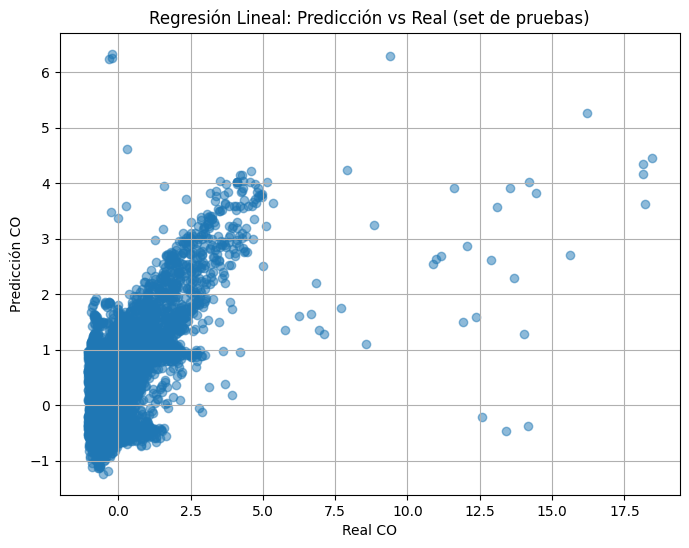

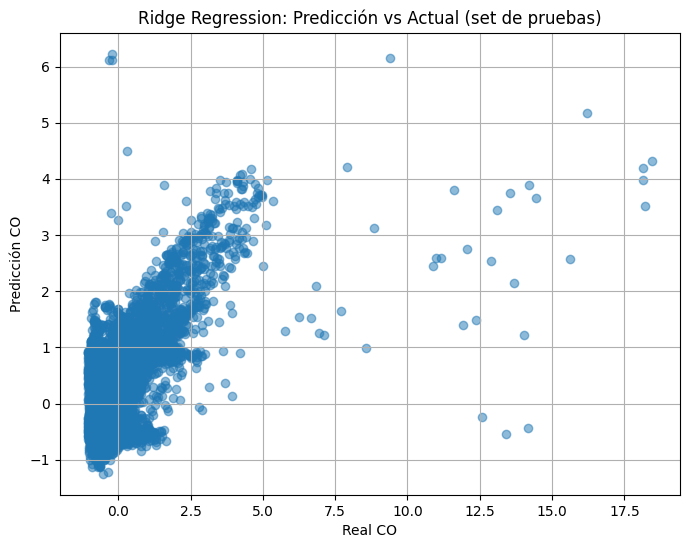

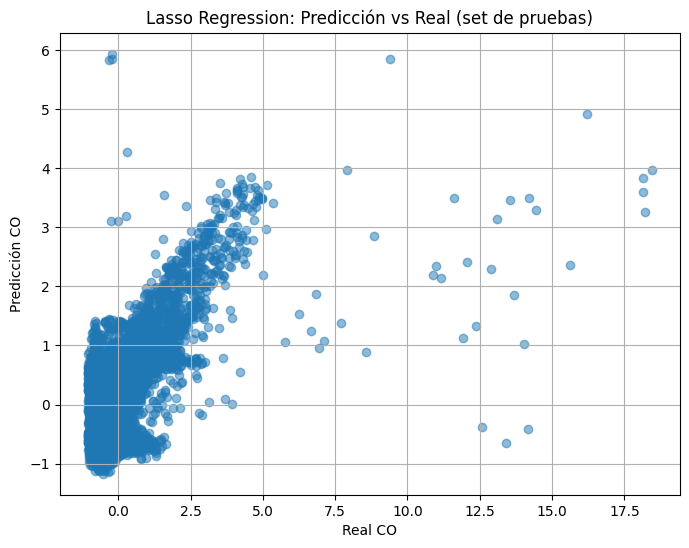

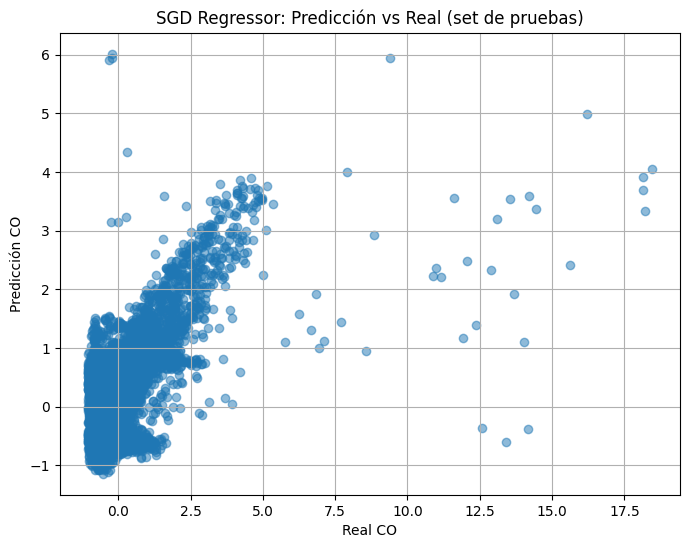

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred_lr, alpha=0.5)
plt.title('Regresión Lineal: Predicción vs Real (set de pruebas)')
plt.xlabel('Real CO')
plt.ylabel('Predicción CO')
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred_ridge, alpha=0.5)
plt.title('Ridge Regression: Predicción vs Actual (set de pruebas)')
plt.xlabel('Real CO')
plt.ylabel('Predicción CO')
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred_lasso, alpha=0.5)
plt.title('Lasso Regression: Predicción vs Real (set de pruebas)')
plt.xlabel('Real CO')
plt.ylabel('Predicción CO')
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred_sgd, alpha=0.5)
plt.title('SGD Regressor: Predicción vs Real (set de pruebas)')
plt.xlabel('Real CO')
plt.ylabel('Predicción CO')
plt.grid(True)
plt.show()

La dispersión de los puntos nos indica la precisión de las predicciones. En estas gráficas, se observa una dispersión considerable, especialmente a medida que los valores de CO reales aumentan. Esto se alinea con los valores de R2 obtenidos, que son relativamente bajos (por debajo de 0.4 para todos los modelos en el conjunto de prueba), indicando que los modelos explican una proporción limitada de la variabilidad en las emisiones de CO.

## Proceso, Resultados e Impacto del Proyecto

En este proyecto, abordamos la predicción de emisiones de CO de turbinas de gas utilizando modelos de regresión de Machine Learning. El proceso se inició con la carga del conjunto de datos "Gas Turbine CO and NOx Emission Data Set" del repositorio de UCI. Tras una exploración inicial que confirmó la ausencia de valores nulos y la naturaleza numérica de las variables, procedimos a estandarizar las características y la variable objetivo (CO) para asegurar que las diferencias en la escala no afectaran el rendimiento de los modelos.

Siguiendo la metodología propuesta en trabajos previos [(Kaya et al., 2019)](https://www.researchgate.net/publication/344718002_Predicting_CO_and_NOxemissions_from_gas_turbines_novel_data_and_abenchmark_PEMS) con este conjunto de datos, dividimos la información cronológicamente: los años 2014 y 2015 se destinaron al entrenamiento, 2013 a la validación y 2011 y 2012 a las pruebas. Posteriormente, entrenamos y ajustamos modelos de Regresión Lineal, Ridge, Lasso y SGD Regressor utilizando Grid Search con validación cruzada para optimizar sus hiperparámetros en el conjunto de entrenamiento y validación.

Finalmente, evaluamos el desempeño de los mejores modelos obtenidos sobre el conjunto de pruebas, calculando el Error Cuadrático Medio (MSE) y el coeficiente de determinación (R2). Los resultados en el conjunto de pruebas fueron los siguientes:
  - Regresión Lineal (MSE: 0.7485, R2: 0.2239),
  - Ridge (MSE: 0.7130, R2: 0.2607),
  - Lasso (MSE: 0.6243, R2: 0.3528) y
  - SGD Regressor (MSE: 0.6423, R2: 0.3340).
  
Estos resultados sugieren que, si bien los modelos logran capturar algo de la variabilidad en las emisiones de CO (evidenciado por los valores de R2 por encima de cero), aún existe un margen significativo para mejorar la precisión predictiva, como lo indica el MSE.

El impacto potencial de modelos predictivos precisos en este ámbito es considerable, permitiendo una mejor monitorización y control de las emisiones, la optimización de la operación de las turbinas para reducir la contaminación y el cumplimiento de normativas ambientales.

## Comparación con Otros Autores y Causas de las Métricas Obtenidas

Al comparar los resultados obtenidos con los de otros autores que reportan métricas de MSE 0.927 y R2 0.584 para la predicción de CO, observamos que las métricas de R2 obtenidas no son notablemente inferiores, aunque nuestro MSE es más bajo. Es importante recordar que el MSE mide el error promedio al cuadrado, mientras que el R2 representa la proporción de la varianza de la variable objetivo que es predecible a partir de las características.

Un MSE más bajo en nuestro caso indica que, en promedio, nuestras predicciones están más cerca de los valores reales en términos de la magnitud del error cuadrático. Sin embargo, un R2 más bajo sugiere que nuestros modelos explican una menor proporción de la variabilidad total. Las posibles causas de estas métricas en nuestro proyecto podrían incluir:

- **Selección de Características**: Aunque utilizamos todas las características disponibles, es posible qque se pueda realizar una ingeniería de características más profunda, reducir la dimensioalidad o seleccionando un subconjunto de características más relevante para la predicción de CO.
- **Técnicas de Modelado:** Si bien se exploraron modelos de regresión lineal y regularizada, es posible que otros modelos más complejos o no lineales (como árboles de decisión, boosting, redes neuronales) sean más adecuados para capturar relaciones no lineales en los datos.
- **Hiperparámetros y Ajuste:** Aunque se usó el Grid Search, el espacio de hiperparámetros explorado o la estrategia de validación cruzada podrían diferir, llevando a encontrar configuraciones de modelo que generalicen mejor.
- **Preprocesamiento de Datos:** Pequeñas diferencias en el proceso de estandarización o en el manejo de posibles valores atípicos pudo influir en el rendimiento.
- **División de Datos:** Aunque se siguió la división cronológica recomendada, ligeras variaciones en la implementación de la división podrían tener un impacto menor.